# Визначення часу проведення експерименту

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

mean_sets=pd.read_csv("wait_times_mean.csv",index_col=0)
mean_sets.head()

,Run_0,Run_1,Run_2,Run_3
Time_Step,,,,
100.0,19.729055,19.861442,17.499087,20.149900
200.0,23.044463,23.297494,20.894907,26.402784
300.0,21.611242,21.261020,25.608984,24.699729
400.0,25.751427,23.602701,24.067982,26.150683
500.0,27.997396,25.930601,25.396210,25.239147


Функція визначення останнього індексу, на якому різниця між максимальним і мінімальним значенням моделі менша за певний поріг

In [2]:
def threshold(dataframe):
    fraction=0.05

    df=dataframe
    mean_curve = df.mean(axis=1)
    max_curve = df.max(axis=1)
    min_curve = df.min(axis=1)

    # Find last index where error exceeds (or 1% relative error)
    unstable = df[(max_curve - min_curve).abs() > mean_curve*fraction].index
    t_steady = unstable[-1] if not unstable.empty else 0
    print(f"Steady-state threshold T_model = {t_steady}")

Зчитування файлів:

In [3]:
df_mean_store=pd.read_csv("wait_times_mean.csv",index_col=0)
df_std_store=pd.read_csv("wait_times_std.csv",index_col=0)
df_mean_system=pd.read_csv("wait_times_mean_system.csv",index_col=0)
df_std_system=pd.read_csv("wait_times_std_system.csv",index_col=0)
df_small_load=3.-pd.read_csv("small_planes_load.csv",index_col=0)
df_big_load=2.-pd.read_csv("big_planes_load.csv",index_col=0)

Визначення порогу

In [4]:
print("Threshold for average storage wait time:")
threshold(df_mean_store)
print("\nThreshold for std storage wait time:")
threshold(df_std_store)
print("\nThreshold for average system wait time:")
threshold(df_mean_system)
print("\nThreshold for std system wait time:")
threshold(df_std_system)
print("\nThreshold for average small plane load:")
threshold(df_small_load)
print("\nThreshold for average big plane load:")
threshold(df_big_load)

Threshold for average storage wait time:
Steady-state threshold T_model = 4500.0

Threshold for std storage wait time:
Steady-state threshold T_model = 2100.0

Threshold for average system wait time:
Steady-state threshold T_model = 5500.0

Threshold for std system wait time:
Steady-state threshold T_model = 16800.0

Threshold for average small plane load:
Steady-state threshold T_model = 5900.0

Threshold for average big plane load:
Steady-state threshold T_model = 83400.0


Зображення графіків відгуку моделі залежно від часу

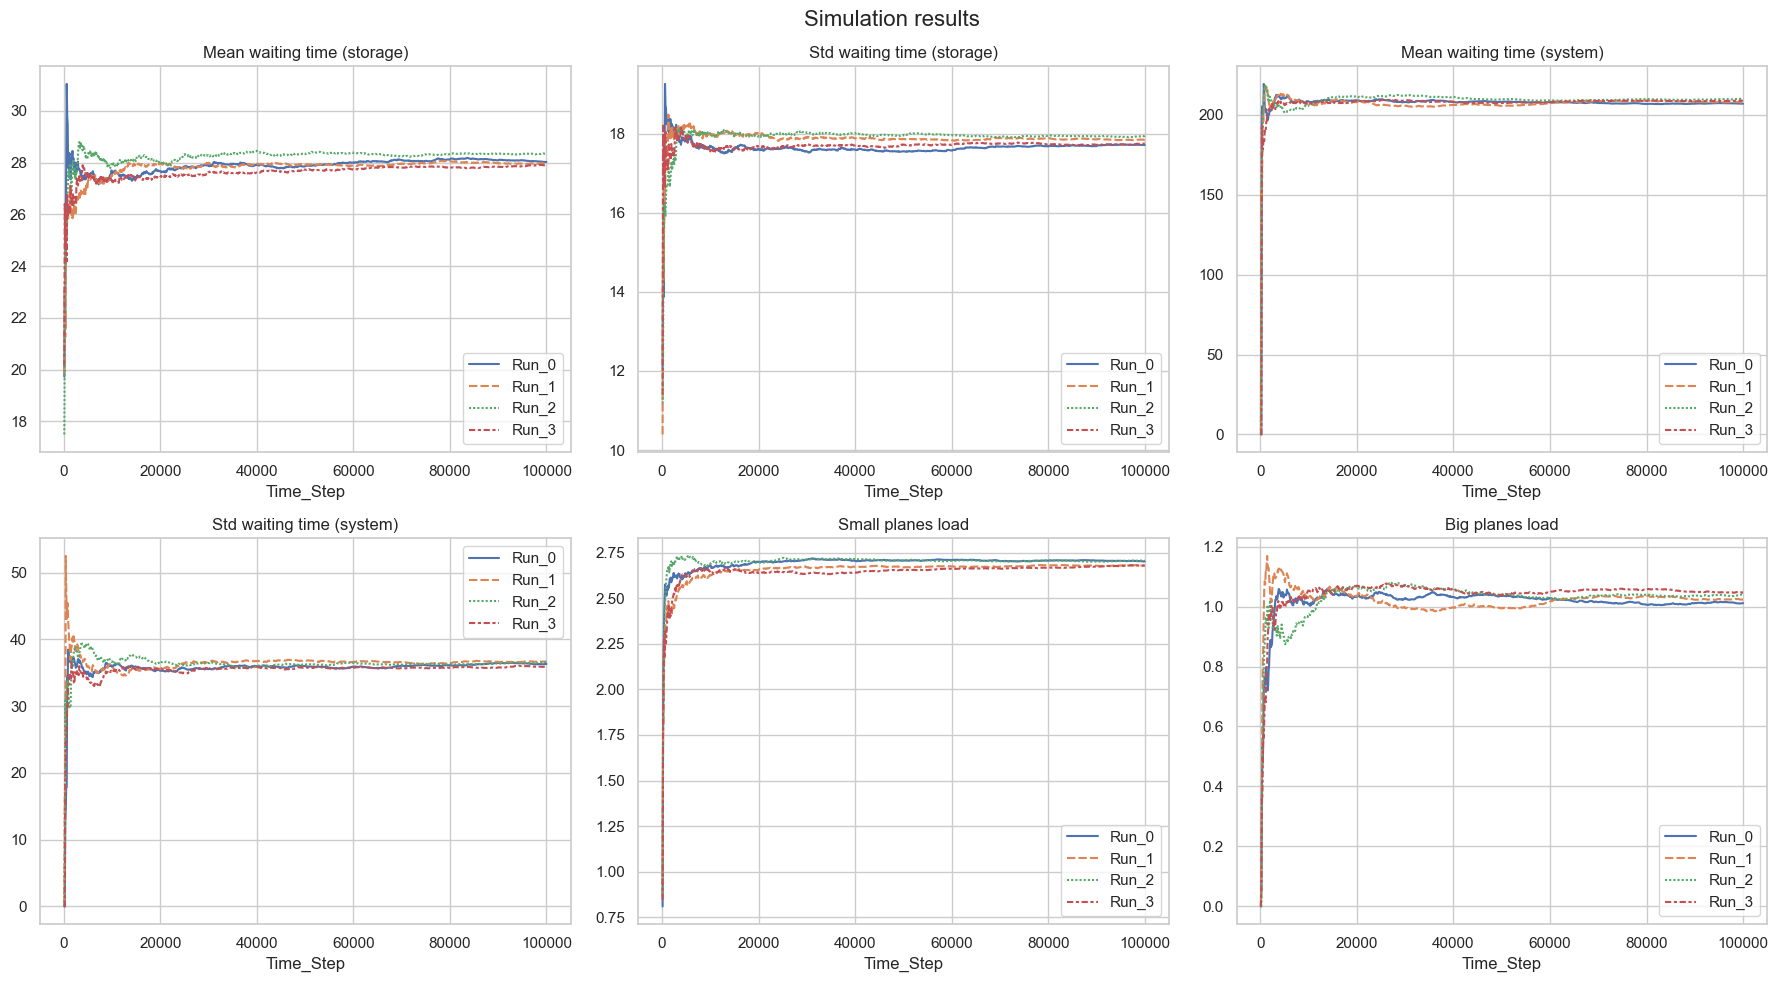

In [5]:
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.lineplot(data=df_mean_store, ax=axes[0, 0])
axes[0, 0].set_title("Mean waiting time (storage)")

sns.lineplot(data=df_std_store, ax=axes[0, 1])
axes[0, 1].set_title("Std waiting time (storage)")

sns.lineplot(data=df_mean_system, ax=axes[0, 2])
axes[0, 2].set_title("Mean waiting time (system)")

sns.lineplot(data=df_std_system, ax=axes[1, 0])
axes[1, 0].set_title("Std waiting time (system)")

sns.lineplot(data=df_small_load, ax=axes[1, 1])
axes[1, 1].set_title("Small planes load")

sns.lineplot(data=df_big_load, ax=axes[1, 2])
axes[1, 2].set_title("Big planes load")

fig.suptitle("Simulation results", fontsize=16)

plt.tight_layout()
plt.show()

# Визначення розподілу часу очікування всередині одного запуску

Час очікування контейнеру перед початком завантаження

<Axes: ylabel='Count'>

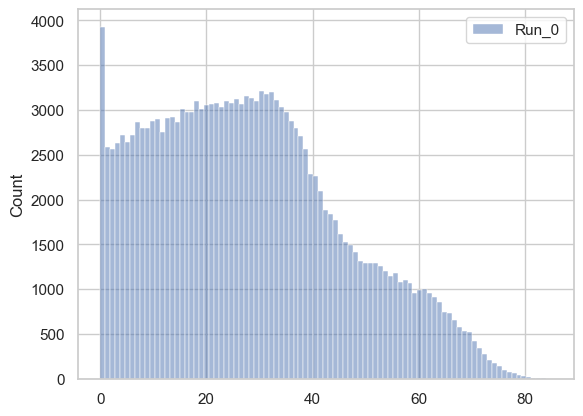

In [6]:
df=pd.read_csv("single_store_wait_time.csv")
sns.histplot(df)

Час очікування від прибуття до вантажного аеропорту до точки призначення

<Axes: ylabel='Count'>

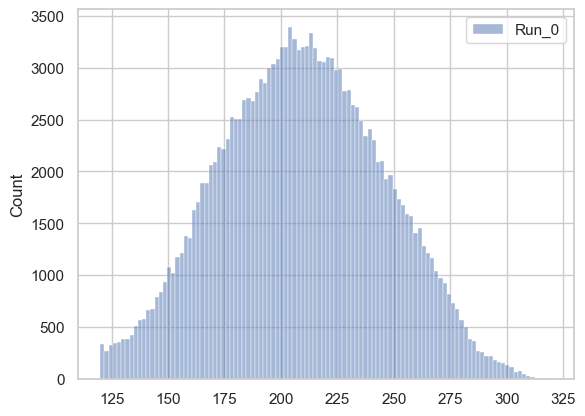

In [7]:
df=pd.read_csv("single_system_wait_time.csv")
sns.histplot(df)

## Тести Хі-квадрату

Параметри розподілу Ерланга: k=2, loc=-5.3455262502348555, scale=10.703829232335671
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 117689.78283971884, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=28.373079500830865, std=17.751983223742595
Подібність розподілу Нормального: dof: 9, chi2_stat: 6393.083144642318, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=28.373079500830865
Chi-squared test (Exponential): dof: 9, chi2_stat: 38133.14388793325, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.9903466872442718, loc=0, scale=20.718135141315457
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 45306.53832684218, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу
 

Двовершинний розподіл (Суміш 2-х нормальних):
  Компонента 1: w=0.56, mean=16.7823, std=10.2147
  Компонен

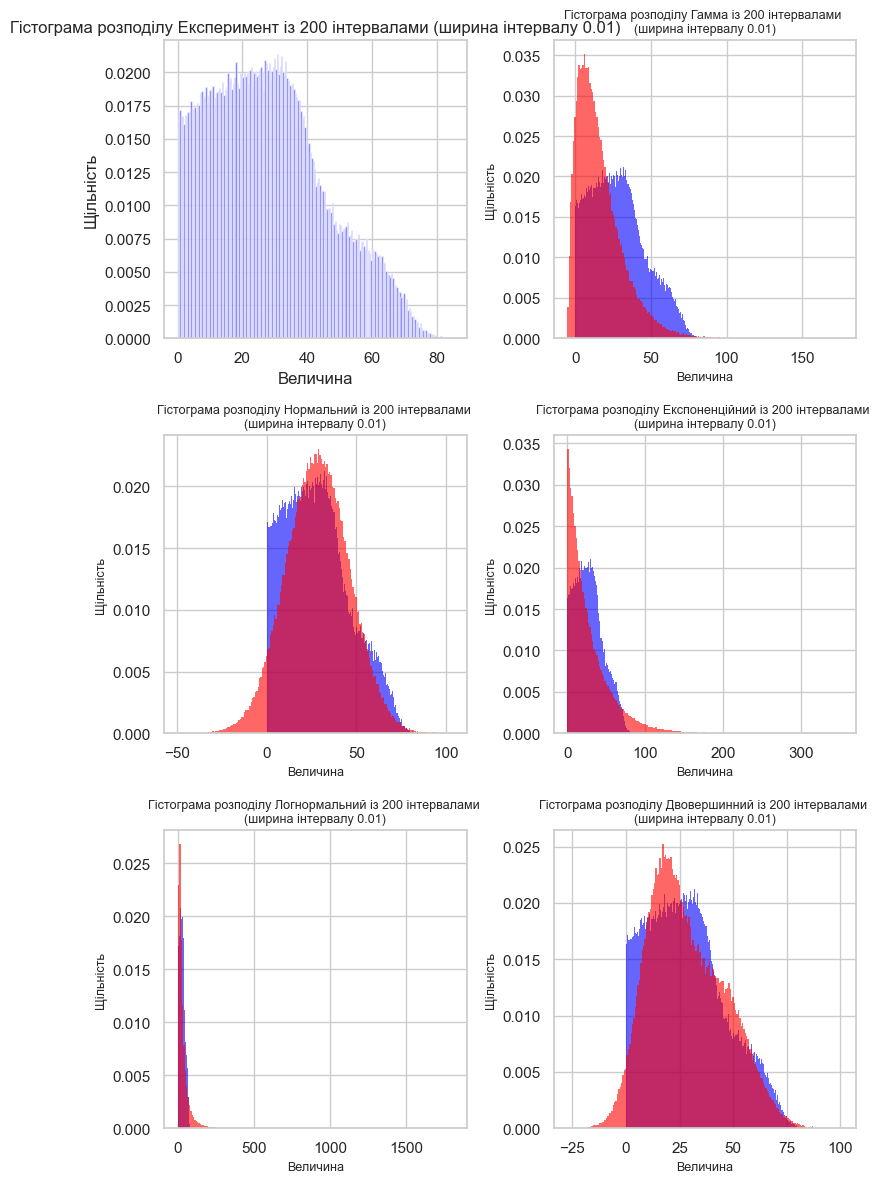

In [8]:
df=pd.read_csv("single_store_wait_time.csv")
df=df[df>0].dropna()
from Distributions import distribution_analysis
distribution_analysis(df.iloc[:,0])

Параметри розподілу Ерланга: k=2, loc=-2877.2934435939833, scale=0.4224444654335955
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 1499219.9999995807, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=209.07586072897772, std=36.108473938176765
Подібність розподілу Нормального: dof: 9, chi2_stat: 502.325369191915, chi2_treshold: 16.918977604620448
1.8268405139719714e-102<0.05: відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=209.07586072897772
Chi-squared test (Exponential): dof: 9, chi2_stat: 497315.75303157704, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.17813200276372315, loc=0, scale=205.8642283928735
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 2090.0908872614104, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу
 

Двовершинний розподіл (Суміш 2-х нормальних):
  Компонента 1: w=0.50, mean=184.0271, 

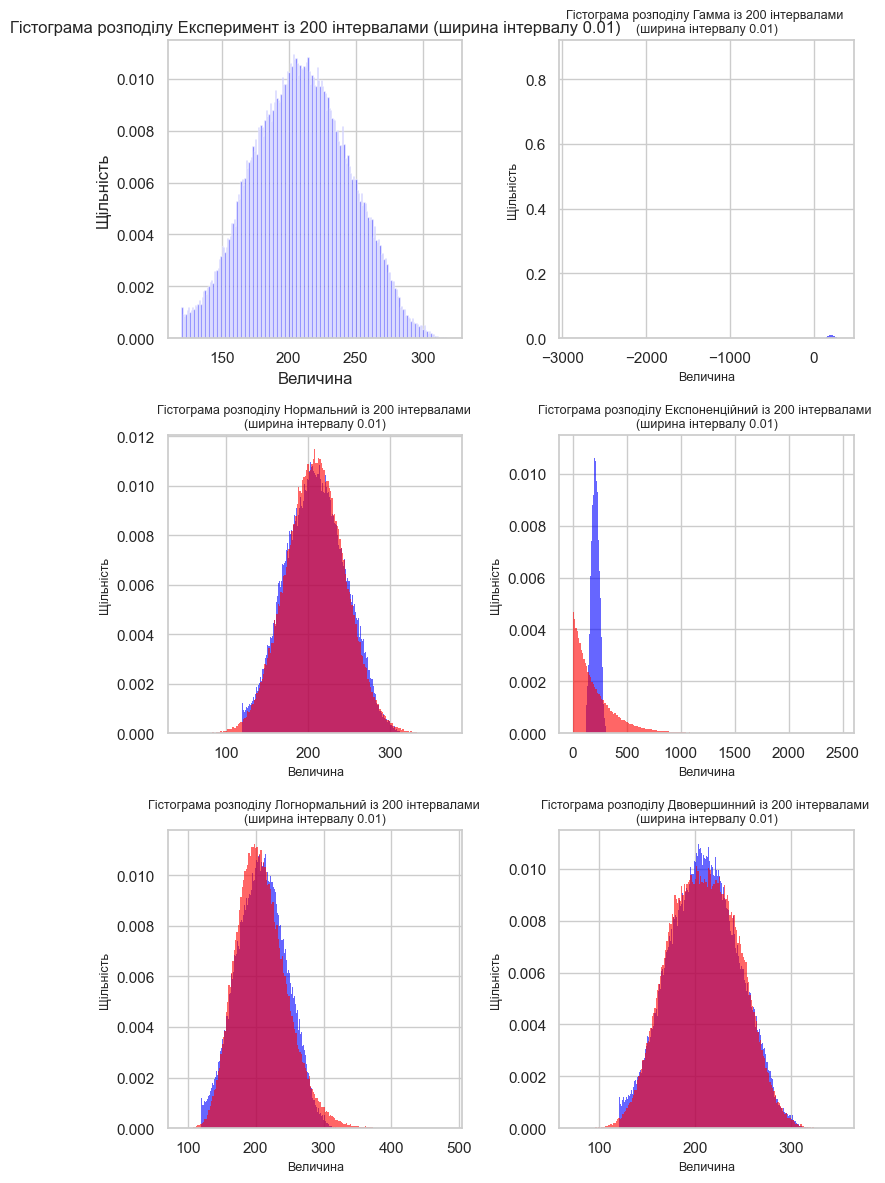

In [9]:
df=pd.read_csv("single_system_wait_time.csv")
df=df[df>0].dropna()
from Distributions import distribution_analysis
distribution_analysis(df.iloc[:,0])

In [10]:
import sys
import importlib
importlib.reload(sys.modules['Distributions'])
import numpy as np
df=pd.read_csv("single_store_wait_time.csv")
df=pd.DataFrame.to_numpy(df)
df=df.flatten()

df=df[~np.isnan(df)]
df=df[df>0]
df_1=np.random.choice(df,5000)
df_2=np.random.choice(df,5000)
import Distributions
Distributions.chi_squared_check(df_1,Distributions.make_empirical_cdf(df_2))

'dof: 9, chi2_stat: 17.672000000000292, chi2_treshold: 16.918977604620448\n0.03917534277896703<0.05: відхиляємо гіпотезу\n'

In [11]:
import sys
import importlib
importlib.reload(sys.modules['Distributions'])
import numpy as np
df=pd.read_csv("single_system_wait_time.csv")
df=pd.DataFrame.to_numpy(df)
df=df.flatten()

df=df[~np.isnan(df)]
df=df[df>0]
df_1=np.random.choice(df,500)
df_2=np.random.choice(df,500)
import Distributions
Distributions.chi_squared_check(df_1,Distributions.make_empirical_cdf(df_2))

'dof: 9, chi2_stat: 20.559999999999693, chi2_treshold: 16.918977604620448\n0.014754053650353432<0.05: відхиляємо гіпотезу\n'

Параметри розподілу Ерланга: k=2, loc=-4.827902921335276, scale=10.89416565333272
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 297.63999999999356, chi2_treshold: 16.918977604620448
8.264763545060625e-59<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=28.51898294973668, std=17.750419618915206
Подібність розподілу Нормального: dof: 9, chi2_stat: 19.759999999999344, chi2_treshold: 16.918977604620448
0.019452693937429367<0.05: відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=28.51898294973668
Chi-squared test (Exponential): dof: 9, chi2_stat: 127.92000000000083, chi2_treshold: 16.918977604620448
3.173940340680521e-23<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.9345470226101024, loc=0, scale=21.143406881223527
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 115.00000000000037, chi2_treshold: 16.918977604620448
1.4061543179693822e-20<0.05: відхиляємо гіпотезу
 

Двовершинний розподіл (Суміш 2-х но

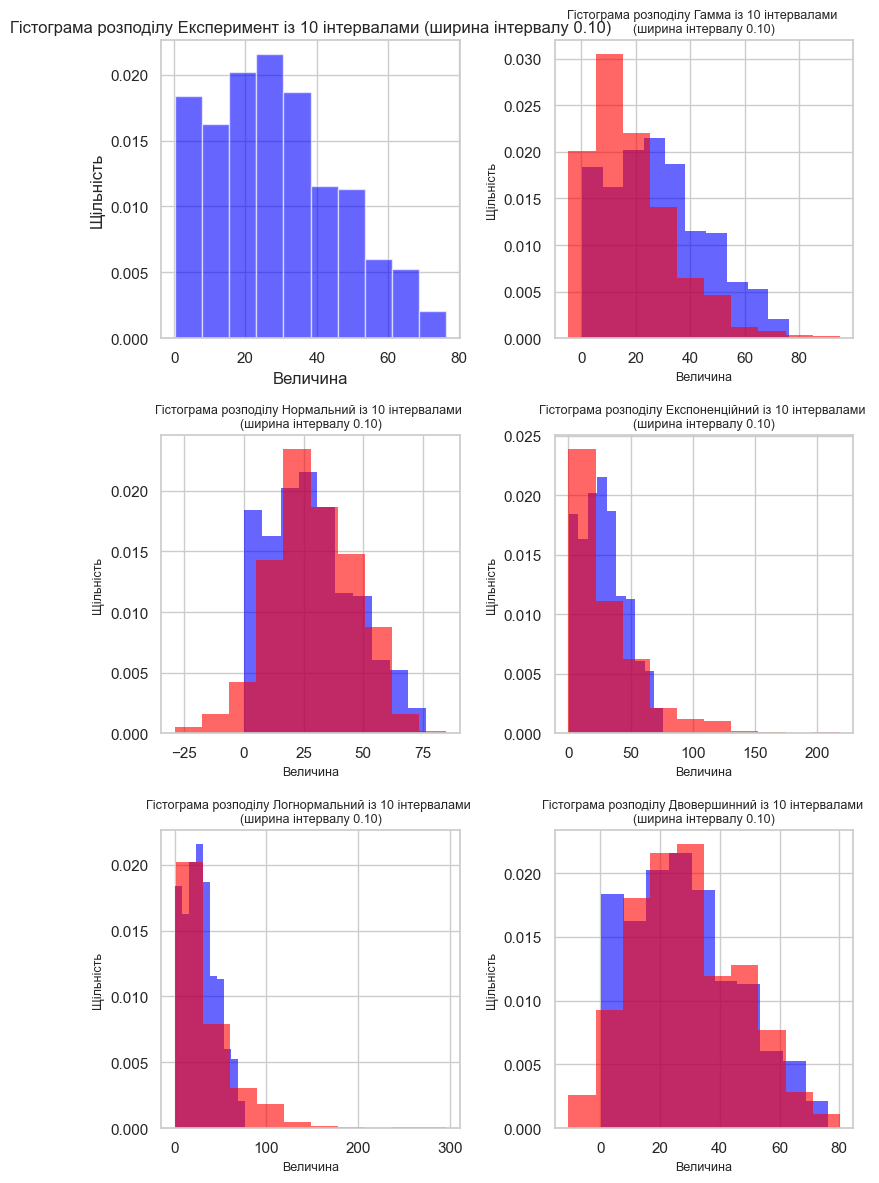

In [12]:
import numpy as np
df=pd.read_csv("single_store_wait_time.csv")
df=pd.DataFrame.to_numpy(df)
df=df.flatten()
df=df[~np.isnan(df)]
df=df[df>0]
df=np.random.choice(df,500)
from Distributions import distribution_analysis
distribution_analysis(df,10)

Параметри розподілу Ерланга: k=2, loc=-22227.833102752054, scale=0.0611000481907828
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 4500.00000006239, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=212.83995162111032, std=37.02849530510604
Подібність розподілу Нормального: dof: 9, chi2_stat: 10.19999999999955, chi2_treshold: 16.918977604620448
0.3345381516340419>=0.05: не відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=212.83995162111032
Chi-squared test (Exponential): dof: 9, chi2_stat: 1457.8000000000013, chi2_treshold: 16.918977604620448
2.5034172016306973e-308<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.1796132922105073, loc=0, scale=209.51725996031732
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 20.640000000000025, chi2_treshold: 16.918977604620448
0.014348428826564863<0.05: відхиляємо гіпотезу
 

Двовершинний розподіл (Суміш 2-х нормальних):
  Ком

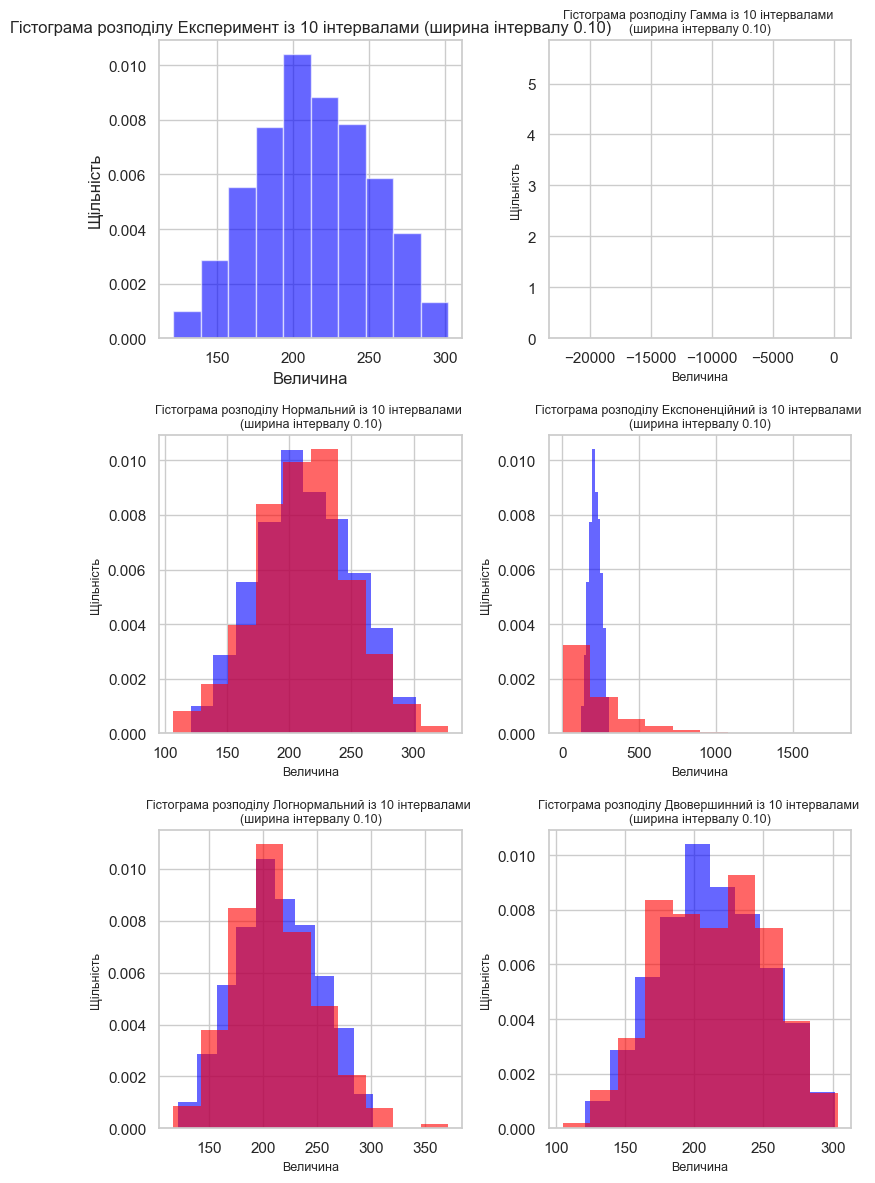

In [13]:
#Час перебування в системі
import numpy as np
df=pd.read_csv("single_system_wait_time.csv")
df=pd.DataFrame.to_numpy(df)
df=df.flatten()
df=df[~np.isnan(df)]
df=df[df>0]
df=np.random.choice(df,500)
from Distributions import distribution_analysis
distribution_analysis(df,10)

In [14]:
import sys
import importlib
importlib.reload(sys.modules['Distributions'])
import numpy as np
df=pd.read_csv("80_system_wait_time.csv")

df=df[df>0]


df_1=np.random.choice(np.array(df.iloc[:,0].dropna()),500)
df_2=np.random.choice(np.array(df.iloc[:,1].dropna()),500)
import Distributions
Distributions.chi_squared_check(df_1,Distributions.make_empirical_cdf(df_2))

'dof: 9, chi2_stat: 15.43999999999976, chi2_treshold: 16.918977604620448\n0.07953751657921153>=0.05: не відхиляємо гіпотезу\n'

Параметри розподілу Ерланга: k=2, loc=-6.984964268232918, scale=10.044959398468443
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 668.4799999999942, chi2_treshold: 16.918977604620448
4.116522413698279e-138<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=29.884538233004477, std=18.24007479071952
Подібність розподілу Нормального: dof: 9, chi2_stat: 37.160000000001034, chi2_treshold: 16.918977604620448
2.464301765870971e-05<0.05: відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=29.884538233004477
Chi-squared test (Exponential): dof: 9, chi2_stat: 127.80000000000226, chi2_treshold: 16.918977604620448
3.3593299478444547e-23<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=1.0021643318876492, loc=0, scale=22.095375273277284
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 130.16000000000005, chi2_treshold: 16.918977604620448
1.0994045611330724e-23<0.05: відхиляємо гіпотезу
 

Двовершинний розподіл (Суміш 2-

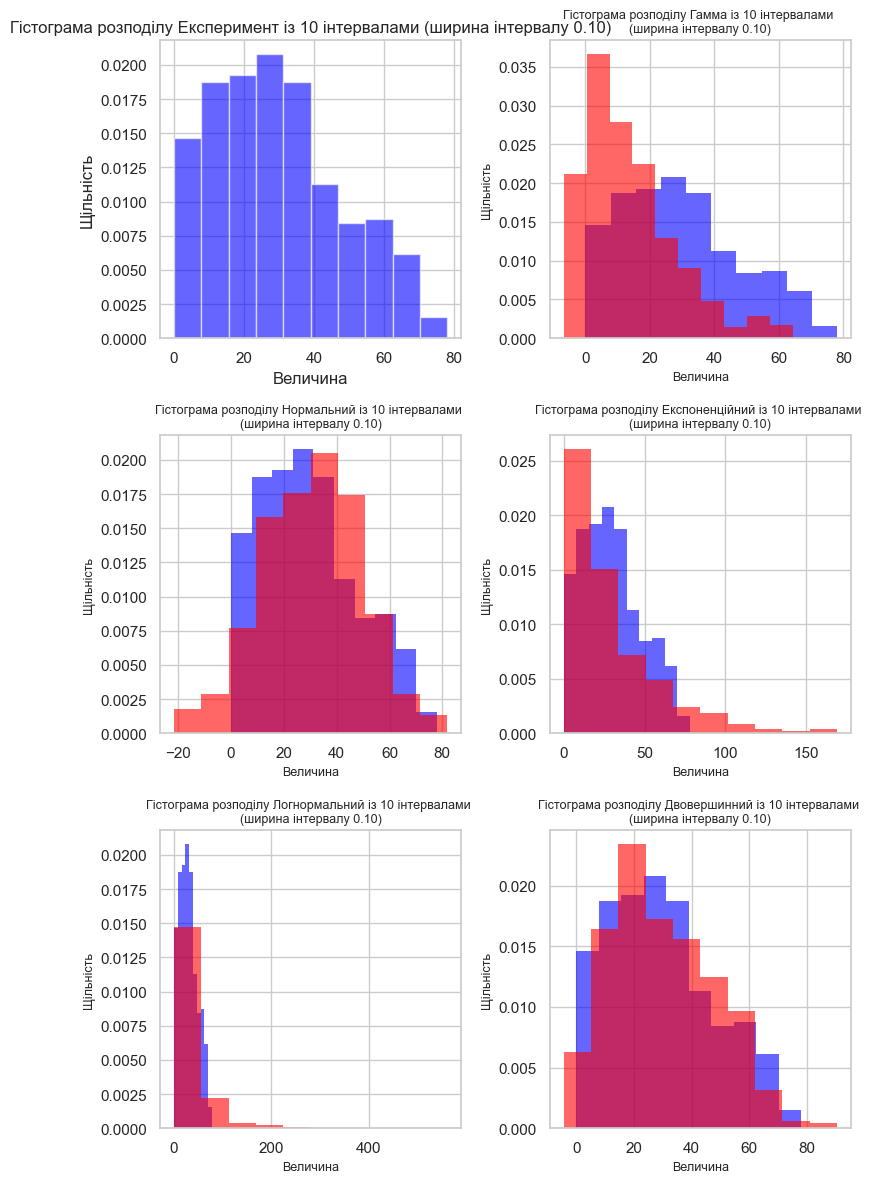

In [15]:
import numpy as np
df=pd.read_csv("80_store_wait_time.csv")
df=pd.DataFrame.to_numpy(df)
df=df.flatten()
df=df[~np.isnan(df)]
df=df[df>0]
df=np.random.choice(df,500)
from Distributions import distribution_analysis
distribution_analysis(df,10)

Параметри розподілу Ерланга: k=2, loc=-517.1529220348198, scale=2.1256441603795118
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 4500.0000000000455, chi2_treshold: 16.918977604620448
0.0<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=207.4455620963723, std=39.27858149048009
Подібність розподілу Нормального: dof: 9, chi2_stat: 9.599999999999998, chi2_treshold: 16.918977604620448
0.3838265173713845>=0.05: не відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=207.4455620963723
Chi-squared test (Exponential): dof: 9, chi2_stat: 1302.840000000001, chi2_treshold: 16.918977604620448
7.535190687760667e-275<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.19481548739576096, loc=0, scale=203.63415792665052
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 7.360000000000644, chi2_treshold: 16.918977604620448
0.5996926007778829>=0.05: не відхиляємо гіпотезу
 

Двовершинний розподіл (Суміш 2-х нормальних):
  Комп

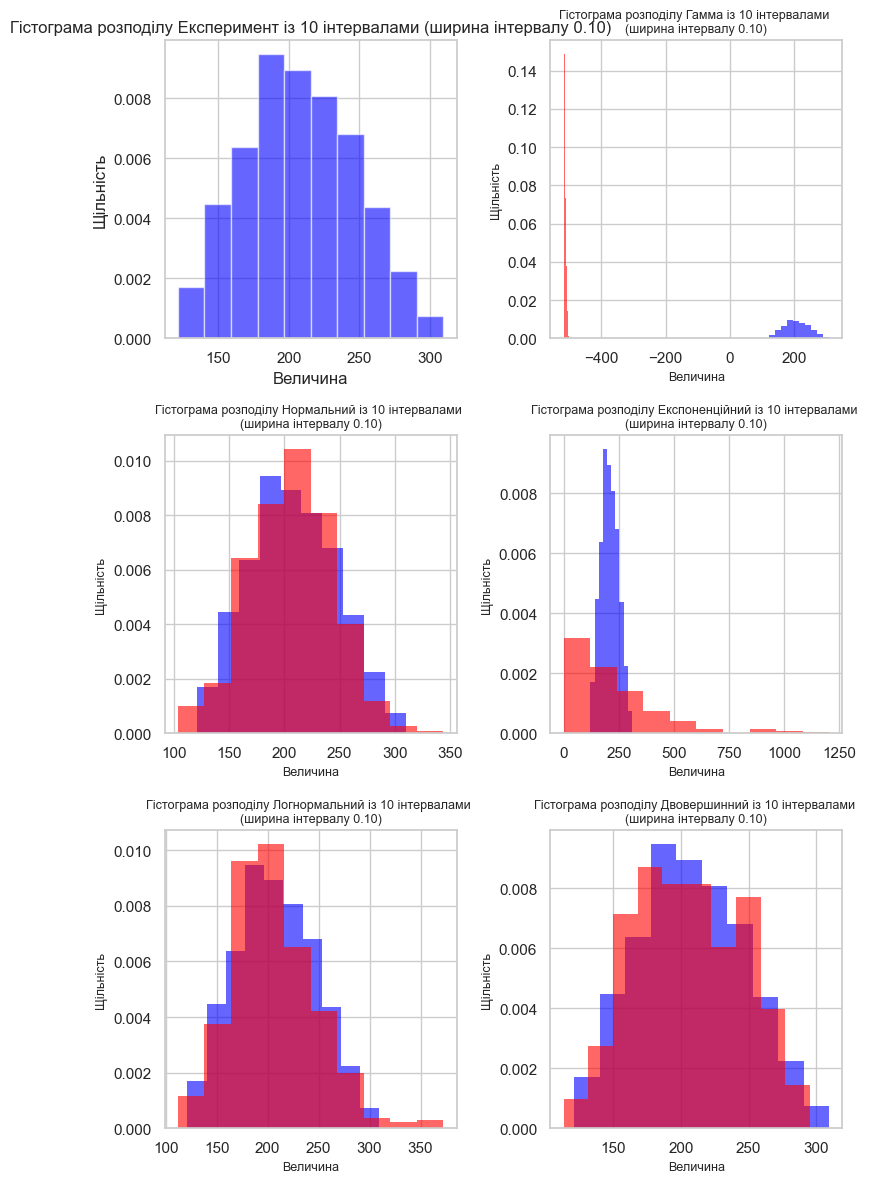

In [16]:
import numpy as np
df=pd.read_csv("80_system_wait_time.csv")
df=pd.DataFrame.to_numpy(df)
df=df.flatten()
df=df[~np.isnan(df)]
df=df[df>0]
df=np.random.choice(df,500)
from Distributions import distribution_analysis
distribution_analysis(df,10)

# Визначення середнього відгуку моделі

In [17]:
df=pd.read_csv("80_parametre_runs.csv")
df.head()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
0,Run_0,83500.0,3,2,0.5,0.0,27.69,205.82,2.681,1.015,55.5,167000.0
1,Run_1,83500.0,3,2,0.5,0.0,28.03,207.84,2.705,1.015,56.0,166320.0
2,Run_2,83500.0,3,2,0.5,0.0,27.99,207.68,2.681,1.028,55.9,166240.0
3,Run_3,83500.0,3,2,0.5,0.0,28.45,210.50,2.701,1.039,56.6,165620.0
4,Run_4,83500.0,3,2,0.5,0.0,28.30,207.91,2.686,1.015,56.3,165660.0


In [18]:
df=df[["AvgStoreWait","AvgSystemWait","SmallUtil","BigUtil"]]
df.describe()

,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil
count,80.000000,80.000000,80.000000,80.000000
mean,28.044625,208.074875,2.694050,1.029025
std,0.153557,1.070308,0.009492,0.016876
min,27.690000,205.440000,2.676000,0.992000
25%,27.960000,207.537500,2.686000,1.016750
50%,28.040000,208.020000,2.693500,1.027000
75%,28.132500,208.660000,2.699000,1.039000
max,28.450000,211.100000,2.727000,1.082000


Визначення типу розподілу середнього часу очікування в аеропорті

Параметри розподілу Ерланга: k=2, loc=26.160851277939656, scale=0.012354431793212956
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 720.0000000000091, chi2_treshold: 16.918977604620448
3.464432376633286e-149<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=28.044625000000003, std=0.15259377239913816
Подібність розподілу Нормального: dof: 9, chi2_stat: 4.000000000013612, chi2_treshold: 16.918977604620448
0.9114125268307833>=0.05: не відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=28.044625000000003
Chi-squared test (Exponential): dof: 9, chi2_stat: 719.9999999999761, chi2_treshold: 16.918977604620448
3.4644323766897688e-149<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.00543864651482158, loc=0, scale=28.044210116045164
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 4.000000000010227, chi2_treshold: 16.918977604620448
0.911412526831006>=0.05: не відхиляємо гіпотезу
 

Двовершинний розподіл (Суміш

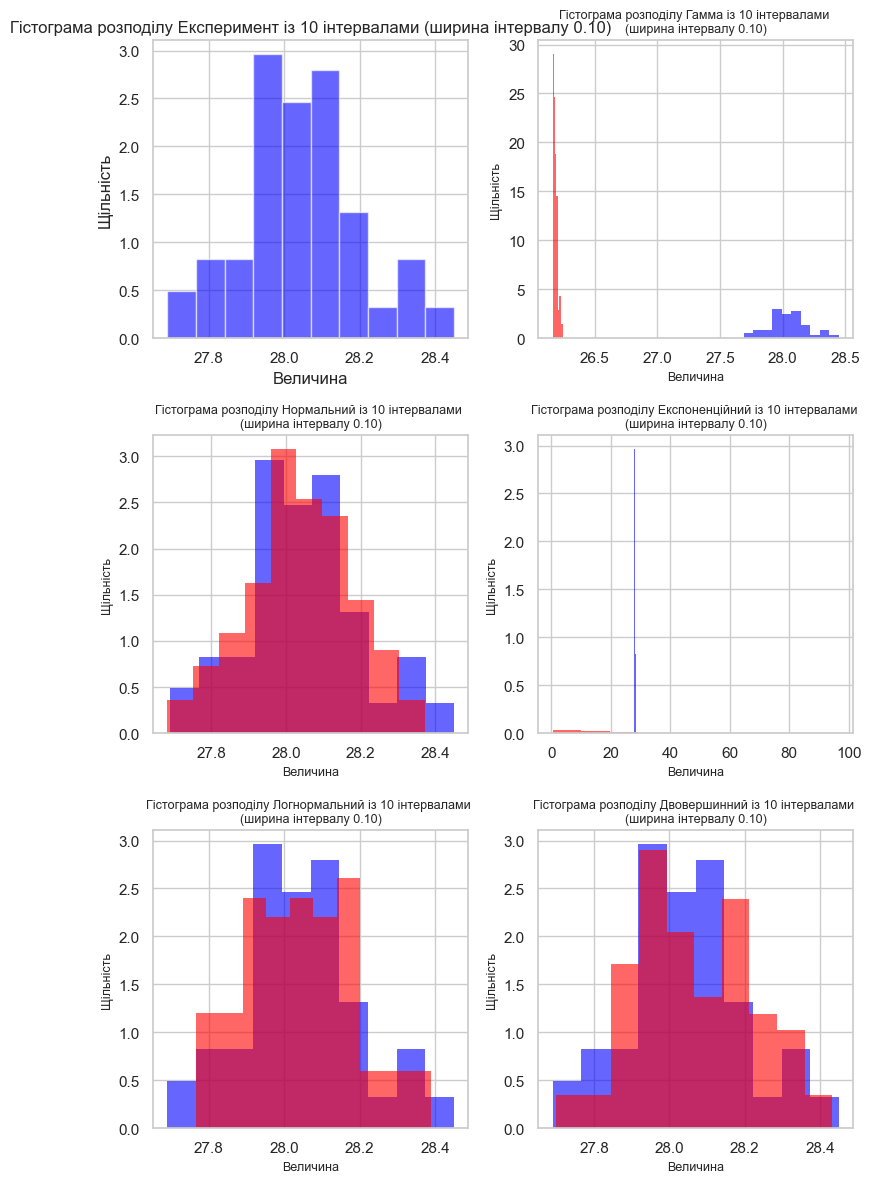

In [19]:
distribution_analysis(df["AvgStoreWait"],10)

Визначення типу розподілу середнього часу очікування до прибуття (життя в системі)

Параметри розподілу Ерланга: k=2, loc=120.65352353729365, scale=0.012941838992265132
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 719.9999999997078, chi2_treshold: 16.918977604620448
3.464432377150115e-149<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=208.07487499999996, std=1.0635976609484428
Подібність розподілу Нормального: dof: 9, chi2_stat: 16.000000000046413, chi2_treshold: 16.918977604620448
0.06688158777315743>=0.05: не відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=208.07487499999996
Chi-squared test (Exponential): dof: 9, chi2_stat: 720.0000000000011, chi2_treshold: 16.918977604620448
3.464432376646913e-149<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.005111469665413057, loc=0, scale=208.0721567835804
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 16.000000000034813, chi2_treshold: 16.918977604620448
0.06688158777339971>=0.05: не відхиляємо гіпотезу
 

Двовершинний розподіл (Су

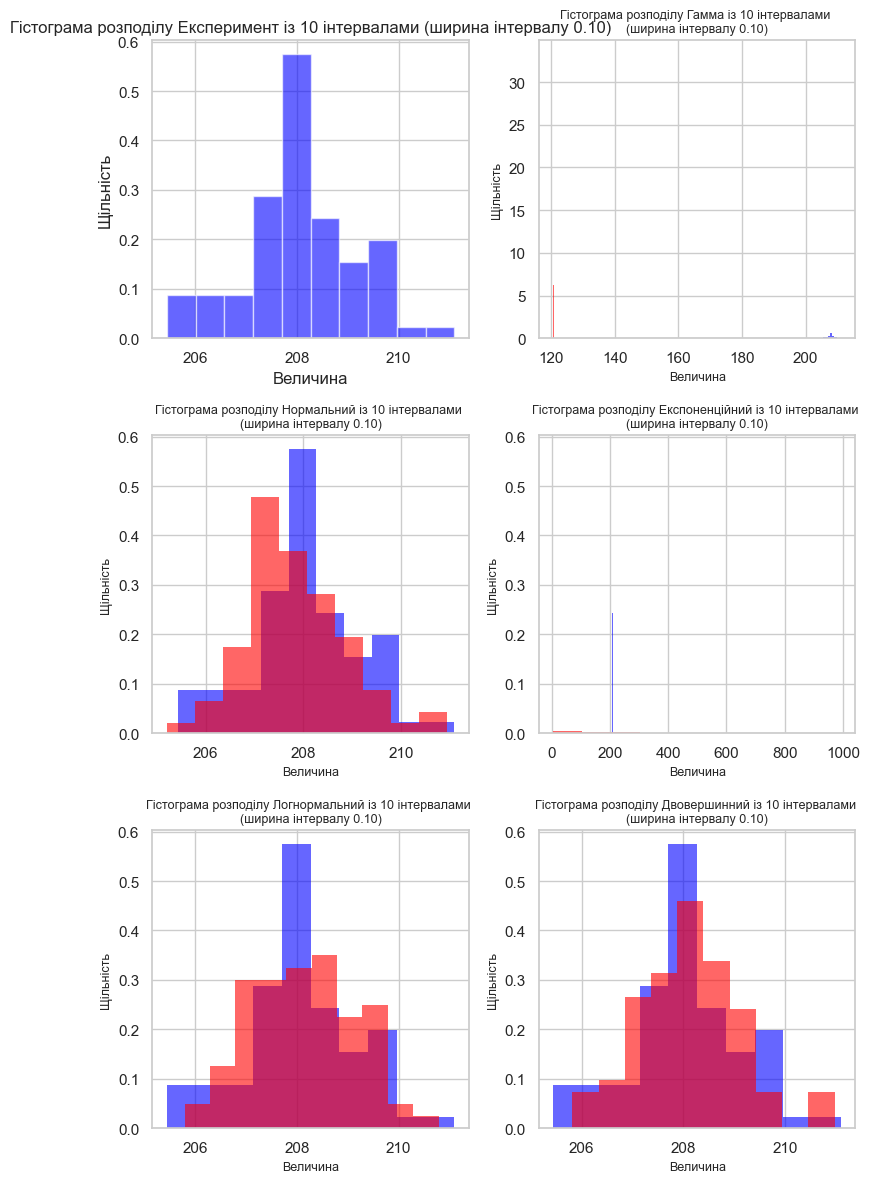

In [20]:
distribution_analysis(df["AvgSystemWait"],10)

Визначення типу розподілу зайнятості малих літаків

Параметри розподілу Ерланга: k=2, loc=2.6672438374456346, scale=0.00334171300542489
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 643.2500000001057, chi2_treshold: 16.918977604620448
1.0835635245101573e-132<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=2.69405, std=0.009432523522366646
Подібність розподілу Нормального: dof: 9, chi2_stat: 22.99999999955067, chi2_treshold: 16.918977604620448
0.006196317390962194<0.05: відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=2.69405
Chi-squared test (Exponential): dof: 9, chi2_stat: 719.9999999999994, chi2_treshold: 16.918977604620448
3.4644323766498755e-149<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.0034970926401881003, loc=0, scale=2.6940335134060316
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 22.9999999991649, chi2_treshold: 16.918977604620448
0.0061963173918285685<0.05: відхиляємо гіпотезу
 

Двовершинний розподіл (Суміш 2-х нормальних):
  Ко

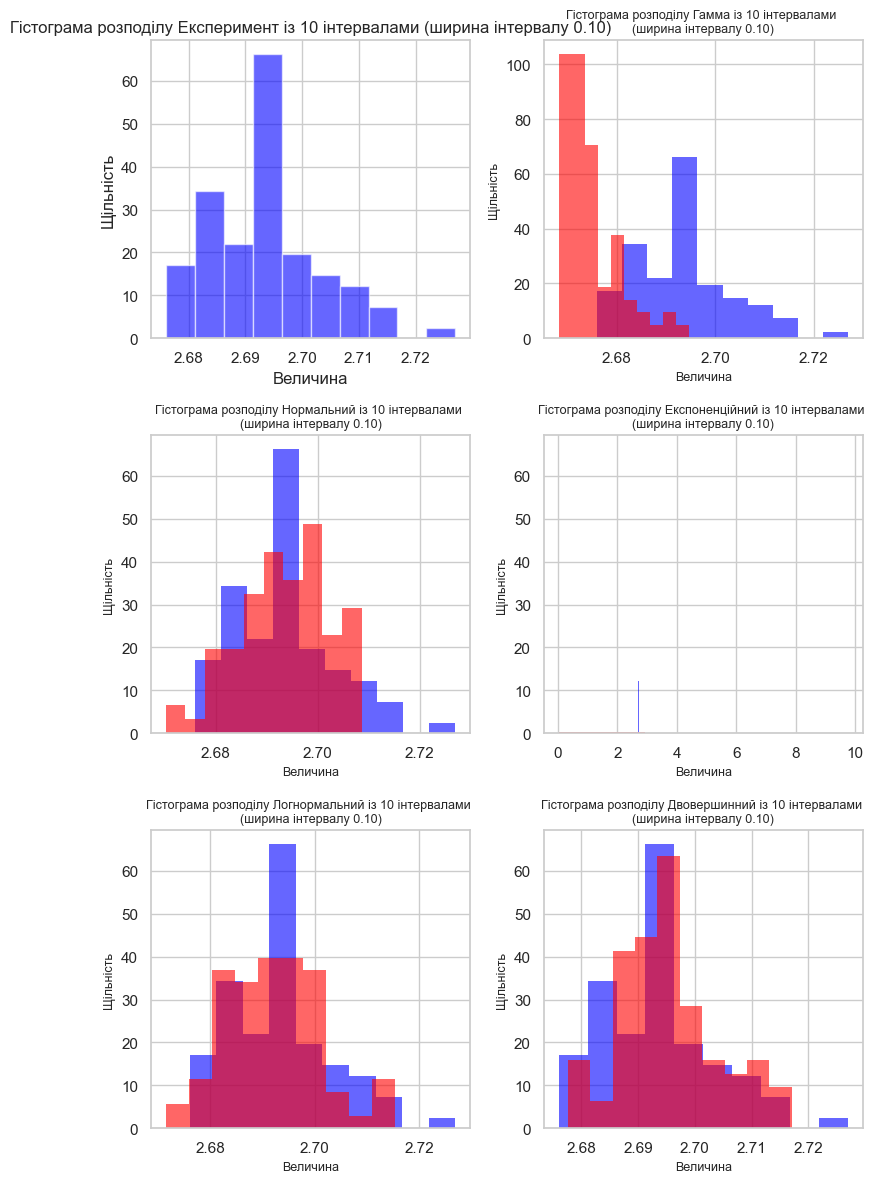

In [21]:
distribution_analysis(df["SmallUtil"],10)

Визначення типу розподілу зайнятості великих літаків

Параметри розподілу Ерланга: k=2, loc=0.9590817448977861, scale=0.004021310936198877
Подібність найбільш відповідного розподілу Ерланга: dof: 9, chi2_stat: 720.0000000374849, chi2_treshold: 16.918977604620448
3.4644323123462945e-149<0.05: відхиляємо гіпотезу


Параметри Нормального розподілу: mean=1.029025, std=0.016770491197338266
Подібність розподілу Нормального: dof: 9, chi2_stat: 8.249999999597641, chi2_treshold: 16.918977604620448
0.5091619454523587>=0.05: не відхиляємо гіпотезу


Параметри Експоненційного розподілу: loc=0.0, scale=1.029025
Chi-squared test (Exponential): dof: 9, chi2_stat: 720.0000000000314, chi2_treshold: 16.918977604620448
3.4644323765949737e-149<0.05: відхиляємо гіпотезу
 

Параметри Логнормального розподілу: s=0.01624085845974112, loc=0, scale=1.0288889890038497
Chi-squared test (Log-Normal): dof: 9, chi2_stat: 8.250000000146459, chi2_treshold: 16.918977604620448
0.5091619453979992>=0.05: не відхиляємо гіпотезу
 

Двовершинний розподіл (Суміш 2-х нормальних):

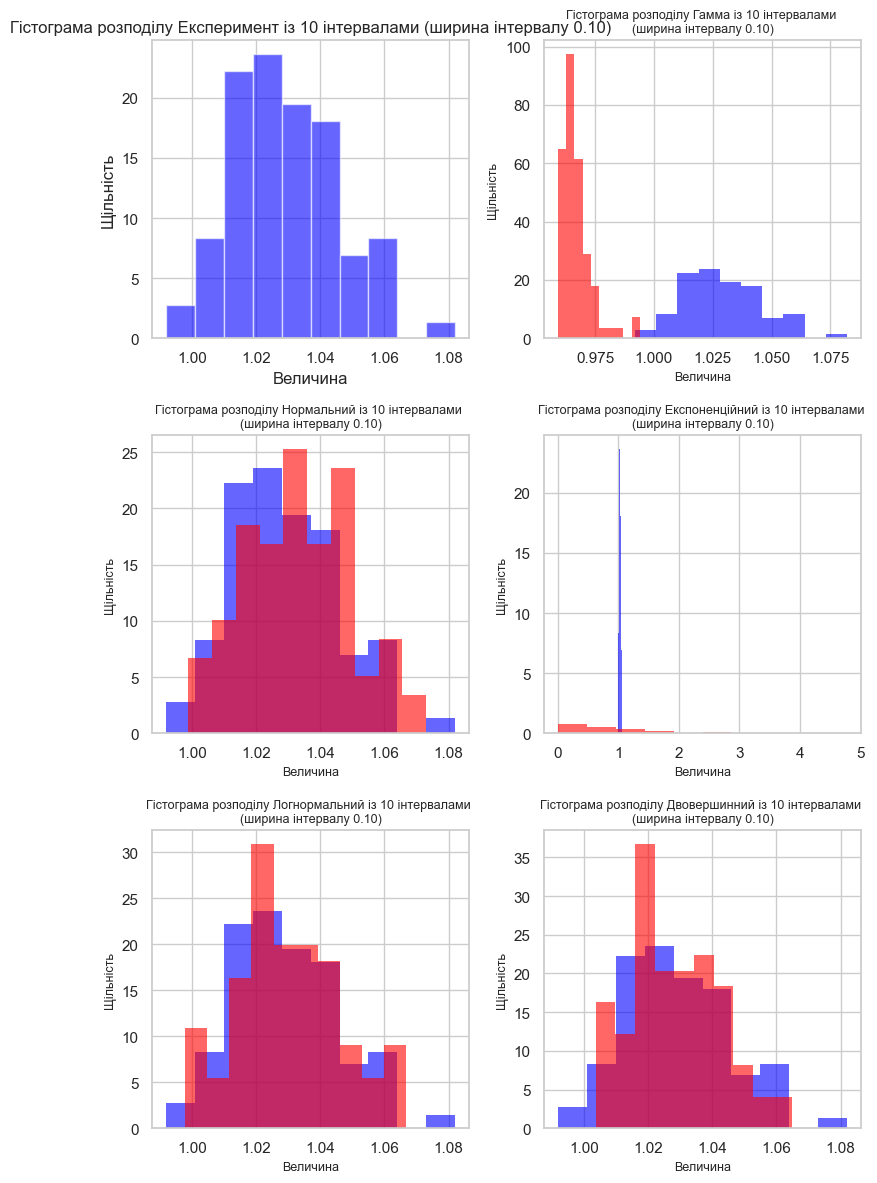

In [22]:
distribution_analysis(df["BigUtil"],10)

# Результати експериментів для дисперсійного аналізу

## Перший експеримент

Порівняння "без часу завантаження" та "1 хвилина на контейнер"

In [23]:
df=pd.read_csv("ExperimentLoadTime.csv")
df.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,160.0,160.0,160.0,160.0,160.00000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000
mean,83500.0,3.0,2.0,0.5,0.50000,2150.674437,2378.016812,2.847462,1.511188,4300.306250,158098.625000
std,0.0,0.0,0.0,0.0,0.50157,2133.580289,2180.913344,0.149790,0.484901,4266.115676,8571.388451
min,83500.0,3.0,2.0,0.5,0.00000,27.610000,205.620000,2.681000,0.990000,55.500000,148220.000000
25%,83500.0,3.0,2.0,0.5,0.00000,28.110000,208.335000,2.697000,1.027000,56.275000,149570.000000
50%,83500.0,3.0,2.0,0.5,0.50000,1970.040000,2197.880000,2.858500,1.529500,3941.500000,158170.000000
75%,83500.0,3.0,2.0,0.5,1.00000,4261.640000,4535.960000,2.997000,1.994000,8528.650000,166650.000000
max,83500.0,3.0,2.0,0.5,1.00000,4796.440000,5071.390000,2.998000,1.995000,9595.600000,167600.000000


In [24]:
factor_1=df.iloc[:80]
factor_2=df.iloc[80:]

In [25]:
factor_1.head()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
0,No_Load_Time_Run_0,83500.0,3,2,0.5,0.0,28.12,207.50,2.693,1.022,56.3,166760.0
1,No_Load_Time_Run_1,83500.0,3,2,0.5,0.0,27.90,209.02,2.688,1.053,55.9,166940.0
2,No_Load_Time_Run_2,83500.0,3,2,0.5,0.0,28.09,206.53,2.714,0.998,56.2,166780.0
3,No_Load_Time_Run_3,83500.0,3,2,0.5,0.0,28.53,208.91,2.697,1.011,56.6,165240.0
4,No_Load_Time_Run_4,83500.0,3,2,0.5,0.0,28.17,209.54,2.691,1.050,56.4,166640.0


In [26]:
factor_2.head()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
80,With_Load_Time_Run_0,83500.0,3,2,0.5,1.0,4443.90,4719.13,2.996,1.994,8862.5,149180.0
81,With_Load_Time_Run_1,83500.0,3,2,0.5,1.0,4134.90,4408.20,2.996,1.994,8293.2,150500.0
82,With_Load_Time_Run_2,83500.0,3,2,0.5,1.0,4197.62,4472.24,2.997,1.995,8387.1,149640.0
83,With_Load_Time_Run_3,83500.0,3,2,0.5,1.0,4140.16,4414.96,2.996,1.994,8241.1,149920.0
84,With_Load_Time_Run_4,83500.0,3,2,0.5,1.0,4549.46,4824.17,2.997,1.994,9118.3,149200.0


In [27]:
factor_1.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,80.0,80.0,80.0,80.0,80.0,80.000000,80.000000,80.000000,80.000000,80.000000,80.000000
mean,83500.0,3.0,2.0,0.5,0.0,28.095750,208.176250,2.698288,1.027950,56.198750,166628.500000
std,0.0,0.0,0.0,0.0,0.0,0.164484,1.157693,0.009393,0.016888,0.303771,443.253506
min,83500.0,3.0,2.0,0.5,0.0,27.610000,205.620000,2.681000,0.990000,55.500000,165240.000000
25%,83500.0,3.0,2.0,0.5,0.0,27.990000,207.332500,2.691000,1.013000,56.000000,166340.000000
50%,83500.0,3.0,2.0,0.5,0.0,28.110000,208.310000,2.697000,1.027000,56.250000,166660.000000
75%,83500.0,3.0,2.0,0.5,0.0,28.182500,208.975000,2.705000,1.038000,56.400000,166945.000000
max,83500.0,3.0,2.0,0.5,0.0,28.530000,210.760000,2.722000,1.066000,56.900000,167600.000000


In [28]:
factor_2.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,80.0,80.0,80.0,80.0,80.0,80.000000,80.000000,80.000000,80.000000,80.000000,80.000000
mean,83500.0,3.0,2.0,0.5,1.0,4273.253125,4547.857375,2.996637,1.994425,8544.413750,149568.750000
std,0.0,0.0,0.0,0.0,0.0,192.904632,193.289414,0.000579,0.000612,385.945617,558.014961
min,83500.0,3.0,2.0,0.5,1.0,3911.550000,4185.000000,2.995000,1.993000,7826.100000,148220.000000
25%,83500.0,3.0,2.0,0.5,1.0,4138.845000,4413.270000,2.996000,1.994000,8261.800000,149195.000000
50%,83500.0,3.0,2.0,0.5,1.0,4263.110000,4537.790000,2.997000,1.994000,8531.000000,149560.000000
75%,83500.0,3.0,2.0,0.5,1.0,4392.057500,4666.710000,2.997000,1.995000,8812.000000,149870.000000
max,83500.0,3.0,2.0,0.5,1.0,4796.440000,5071.390000,2.998000,1.995000,9595.600000,151100.000000


Аналіз Фішера на відмінність

In [29]:
from scipy import stats

df = pd.read_csv("ExperimentLoadTime.csv")


p = 80
f_crit = stats.f.isf(0.05, dfn=1, dfd=2 * (p - 1))

rows = []
for col in ["AvgStoreWait", "AvgSystemWait", "SmallUtil", "BigUtil"]:
    y1, y2 = factor_1[col], factor_2[col]
    y1_m, y2_m = y1.mean(), y2.mean()
    y_m = 0.5 * (y1_m + y2_m)
    
    s_fakt = p * ((y1_m - y_m)**2 + (y2_m - y_m)**2)
    d_zalysh = (y1.var(ddof=1) + y2.var(ddof=1)) / 2
    f_calc = s_fakt / d_zalysh
    
    rows.append({
        "Metric": col,
        "Mean_0": round(y1_m, 3),
        "Mean_1": round(y2_m, 3),
        "S_fakt": round(s_fakt, 3),
        "d_zalysh": round(d_zalysh, 4),
        "F_calc": round(f_calc, 2),
        "F_crit": round(f_crit, 3),
        "Significant": f_calc > f_crit
    })

print(pd.DataFrame(rows).to_string(index=False))

       Metric  Mean_0   Mean_1       S_fakt   d_zalysh    F_calc  F_crit  Significant
 AvgStoreWait  28.096 4273.253 7.208544e+08 18606.1121  38742.88   3.901         True
AvgSystemWait 208.176 4547.857 7.533133e+08 18681.0689  40324.96   3.901         True
    SmallUtil   2.698    2.997 3.561000e+00     0.0000  80401.67   3.901         True
      BigUtil   1.028    1.994 3.736300e+01     0.0001 261657.53   3.901         True


## Другий експеримент

In [30]:
df=pd.read_csv("ExperimentLoadTime_01.csv")
df.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,160.0,160.0,160.0,160.0,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000
mean,83500.0,3.0,2.0,0.5,0.050000,28.298250,213.681250,2.708556,1.097331,56.599375,166602.750000
std,0.0,0.0,0.0,0.0,0.050157,0.290782,5.709404,0.017186,0.070466,0.579904,390.190971
min,83500.0,3.0,2.0,0.5,0.000000,27.730000,205.730000,2.670000,0.996000,55.500000,165520.000000
25%,83500.0,3.0,2.0,0.5,0.000000,28.047500,208.152500,2.694750,1.029000,56.100000,166315.000000
50%,83500.0,3.0,2.0,0.5,0.050000,28.300000,213.270000,2.711000,1.092500,56.600000,166590.000000
75%,83500.0,3.0,2.0,0.5,0.100000,28.522500,219.070000,2.723000,1.164250,57.000000,166865.000000
max,83500.0,3.0,2.0,0.5,0.100000,29.020000,222.660000,2.745000,1.208000,58.000000,167540.000000


In [31]:
factor_1=df.iloc[:80]
factor_2=df.iloc[80:]

In [32]:
factor_1.head()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
0,No_Load_Time_Run_0,83500.0,3,2,0.5,0.0,28.10,207.58,2.685,1.024,56.2,166520.0
1,No_Load_Time_Run_1,83500.0,3,2,0.5,0.0,27.96,208.20,2.697,1.036,56.0,166860.0
2,No_Load_Time_Run_2,83500.0,3,2,0.5,0.0,27.91,208.08,2.684,1.042,55.9,166900.0
3,No_Load_Time_Run_3,83500.0,3,2,0.5,0.0,28.01,208.53,2.686,1.033,55.8,166020.0
4,No_Load_Time_Run_4,83500.0,3,2,0.5,0.0,27.98,207.02,2.689,1.020,56.0,166860.0


In [33]:
factor_2.head()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
80,With_Load_Time_Run_0,83500.0,3,2,0.5,0.1,28.47,218.93,2.721,1.164,57.0,166660.0
81,With_Load_Time_Run_1,83500.0,3,2,0.5,0.1,28.43,218.74,2.718,1.166,56.9,166800.0
82,With_Load_Time_Run_2,83500.0,3,2,0.5,0.1,28.62,217.96,2.719,1.153,57.3,167000.0
83,With_Load_Time_Run_3,83500.0,3,2,0.5,0.1,28.58,220.49,2.717,1.183,57.1,166520.0
84,With_Load_Time_Run_4,83500.0,3,2,0.5,0.1,28.68,218.94,2.738,1.148,57.3,166300.0


In [34]:
factor_1.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,80.0,80.0,80.0,80.0,80.0,80.000000,80.000000,80.000000,80.000000,80.000000,80.000000
mean,83500.0,3.0,2.0,0.5,0.0,28.061750,208.110625,2.694575,1.029063,56.118750,166603.500000
std,0.0,0.0,0.0,0.0,0.0,0.156575,1.154927,0.010651,0.016795,0.306096,395.669917
min,83500.0,3.0,2.0,0.5,0.0,27.730000,205.730000,2.670000,0.996000,55.500000,165520.000000
25%,83500.0,3.0,2.0,0.5,0.0,27.950000,207.062500,2.687750,1.018000,55.900000,166300.000000
50%,83500.0,3.0,2.0,0.5,0.0,28.045000,208.145000,2.695000,1.029000,56.100000,166570.000000
75%,83500.0,3.0,2.0,0.5,0.0,28.152500,208.895000,2.703250,1.041250,56.300000,166940.000000
max,83500.0,3.0,2.0,0.5,0.0,28.460000,210.630000,2.716000,1.070000,56.900000,167460.000000


In [35]:
factor_2.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,80.0,80.0,80.0,80.0,8.000000e+01,80.000000,80.000000,80.000000,80.000000,80.000000,80.000000
mean,83500.0,3.0,2.0,0.5,1.000000e-01,28.534750,219.251875,2.722538,1.165600,57.080000,166602.000000
std,0.0,0.0,0.0,0.0,1.675841e-16,0.179951,1.193322,0.009226,0.016507,0.339545,387.129652
min,83500.0,3.0,2.0,0.5,1.000000e-01,28.140000,215.910000,2.688000,1.115000,56.400000,165580.000000
25%,83500.0,3.0,2.0,0.5,1.000000e-01,28.400000,218.527500,2.717000,1.155000,56.800000,166335.000000
50%,83500.0,3.0,2.0,0.5,1.000000e-01,28.525000,219.080000,2.723000,1.164500,57.000000,166600.000000
75%,83500.0,3.0,2.0,0.5,1.000000e-01,28.660000,219.810000,2.728000,1.178000,57.300000,166840.000000
max,83500.0,3.0,2.0,0.5,1.000000e-01,29.020000,222.660000,2.745000,1.208000,58.000000,167540.000000


Аналіз Фішера

In [36]:
from scipy import stats

df = pd.read_csv("ExperimentLoadTime.csv")


p = 80
f_crit = stats.f.isf(0.05, dfn=1, dfd=2 * (p - 1))

rows = []
for col in ["AvgStoreWait", "AvgSystemWait", "SmallUtil", "BigUtil"]:
    y1, y2 = factor_1[col], factor_2[col]
    y1_m, y2_m = y1.mean(), y2.mean()
    y_m = 0.5 * (y1_m + y2_m)
    
    s_fakt = p * ((y1_m - y_m)**2 + (y2_m - y_m)**2)
    d_zalysh = (y1.var(ddof=1) + y2.var(ddof=1)) / 2
    f_calc = s_fakt / d_zalysh
    
    rows.append({
        "Metric": col,
        "Mean_0": round(y1_m, 3),
        "Mean_1": round(y2_m, 3),
        "S_fakt": round(s_fakt, 3),
        "d_zalysh": round(d_zalysh, 4),
        "F_calc": round(f_calc, 2),
        "F_crit": round(f_crit, 3),
        "Significant": f_calc > f_crit
    })

print(pd.DataFrame(rows).to_string(index=False))

       Metric  Mean_0  Mean_1   S_fakt  d_zalysh  F_calc  F_crit  Significant
 AvgStoreWait  28.062  28.535    8.949    0.0284  314.57   3.901         True
AvgSystemWait 208.111 219.252 4965.098    1.3789 3600.67   3.901         True
    SmallUtil   2.695   2.723    0.031    0.0001  315.04   3.901         True
      BigUtil   1.029   1.166    0.746    0.0003 2689.24   3.901         True


In [37]:
df=pd.read_csv("ExperimentLoadTime_ExtraPlane.csv")
df.describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,160.0,160.00000,160.0,160.0,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000,160.000000
mean,83500.0,3.50000,2.0,0.5,0.050000,27.080500,211.813875,3.115694,0.854063,54.138750,166520.500000
std,0.0,0.50157,0.0,0.0,0.050157,1.000499,3.921328,0.421506,0.173751,2.002262,403.973659
min,83500.0,3.00000,2.0,0.5,0.000000,25.800000,205.520000,2.672000,0.640000,51.500000,165420.000000
25%,83500.0,3.00000,2.0,0.5,0.000000,26.100000,208.045000,2.697000,0.683000,52.175000,166255.000000
50%,83500.0,3.50000,2.0,0.5,0.050000,27.040000,211.880000,3.112500,0.857000,54.250000,166500.000000
75%,83500.0,4.00000,2.0,0.5,0.100000,28.045000,215.650000,3.534250,1.027250,56.100000,166780.000000
max,83500.0,4.00000,2.0,0.5,0.100000,28.380000,217.570000,3.581000,1.072000,56.900000,167420.000000


In [38]:
df.tail()

,Scenario,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
155,With_Load_Time_Run_75,83500.0,4,2,0.5,0.1,26.23,217.41,3.536,0.700,52.3,166220.0
156,With_Load_Time_Run_76,83500.0,4,2,0.5,0.1,26.14,215.31,3.548,0.670,52.3,166420.0
157,With_Load_Time_Run_77,83500.0,4,2,0.5,0.1,26.01,216.05,3.532,0.689,52.0,166320.0
158,With_Load_Time_Run_78,83500.0,4,2,0.5,0.1,25.94,214.02,3.524,0.665,51.8,166340.0
159,With_Load_Time_Run_79,83500.0,4,2,0.5,0.1,25.96,216.81,3.531,0.704,51.9,166560.0


In [39]:
df[80:].describe()

,Time,SmallPlanes,BigPlanes,ArrivalDelay,LoadTime,AvgStoreWait,AvgSystemWait,SmallUtil,BigUtil,AvgStore,DeliveredCargo
count,80.0,80.0,80.0,80.0,8.000000e+01,80.000000,80.000000,80.000000,80.000000,80.000000,80.000000
mean,83500.0,4.0,2.0,0.5,1.000000e-01,26.094125,215.559250,3.535700,0.681600,52.163750,166514.250000
std,0.0,0.0,0.0,0.0,1.675841e-16,0.147397,1.145422,0.014428,0.016053,0.297774,395.265573
min,83500.0,4.0,2.0,0.5,1.000000e-01,25.800000,212.790000,3.504000,0.640000,51.500000,165600.000000
25%,83500.0,4.0,2.0,0.5,1.000000e-01,25.977500,214.685000,3.527750,0.670000,51.900000,166260.000000
50%,83500.0,4.0,2.0,0.5,1.000000e-01,26.100000,215.660000,3.534500,0.683000,52.150000,166480.000000
75%,83500.0,4.0,2.0,0.5,1.000000e-01,26.200000,216.545000,3.541500,0.691000,52.400000,166745.000000
max,83500.0,4.0,2.0,0.5,1.000000e-01,26.410000,217.570000,3.581000,0.725000,53.100000,167420.000000
